# Individual Case Study - Medical Cost

**Course:** MATH7810 Python for Data Science (AY2026/27)

This notebook adapts the structure of the structural demonstration to the `MedicalCost.csv` dataset. Each row represents one insurance beneficiary, and `charges` is the medical cost to be explained.

## 1.1 Background and general information

The file `MedicalCost.csv` contains 1,338 rows and seven variables. It records demographic and health-related factors that may be associated with individual medical insurance charges.

| Column | Variable Types and Meaning |
|---|---|
| `age` | Discrete integer. Age of the beneficiary in years. |
| `sex` | Nominal binary. Sex of the beneficiary: `female` or `male`. |
| `bmi` | Continuous float. Body mass index. |
| `children` | Discrete integer. Number of dependents covered by the insurance plan. |
| `smoker` | Nominal binary. Whether the beneficiary is a smoker: `yes` or `no`. |
| `region` | Nominal categories. Residential region: northeast, northwest, southeast, or southwest. |
| `charges` | Continuous float. Individual medical cost billed by insurance. |

### Shape and missing values

In [1]:
import pandas as pd

# One row represents one insurance beneficiary.
df = pd.read_csv("MedicalCost.csv")

print("rows, columns:", df.shape)
print("missing values:")
print(df.isna().sum())

rows, columns: (1338, 7)
missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


### Categorical variables and percentages

For each category, the count and percentage are shown. Percentages use the number of observed (non-missing) rows as the denominator.

In [2]:
categorical = ["sex", "smoker", "region"]

category_tables = {}
for column in categorical:
    category_table = pd.DataFrame({
        "Count": df[column].value_counts(dropna=False),
        "Percentage": (df[column].value_counts(normalize=True, dropna=False) * 100).round(1),
    })
    category_table.index.name = column
    category_tables[column] = category_table
    print(column)
    print(category_table.to_string())
    print()

sex
        Count  Percentage
sex                      
male      676        50.5
female    662        49.5

smoker
        Count  Percentage
smoker                   
no       1064        79.5
yes       274        20.5

region
           Count  Percentage
region                      
southeast    364        27.2
southwest    325        24.3
northwest    325        24.3
northeast    324        24.2



## 1.2 Numerical descriptive statistics

Age, BMI, number of children, and insurance charges are summarised using sample mean, sample standard deviation, and the five-number summary: minimum, first quartile, median, third quartile, and maximum. The sample standard deviation uses `n - 1` in its denominator.

### Numerical variables: mean and standard deviation

In [3]:
numeric = ["age", "bmi", "children", "charges"]

numerical_summary = df[numeric].agg(["count", "mean", "std", "min", "median", "max"]).T
numerical_summary = numerical_summary.rename(columns={
    "count": "Sample size",
    "mean": "Sample mean",
    "std": "Sample standard deviation",
    "min": "Minimum",
    "median": "Median",
    "max": "Maximum",
})
print(numerical_summary.round(3).to_string())

five = df[numeric].quantile([0, 0.25, 0.5, 0.75, 1]).T
five.columns = ["Minimum", "Q1", "Median", "Q3", "Maximum"]
print("\nFive-number summary:")
print(five.round(2).to_string())

categorical = ["sex", "smoker", "region"]

for column in categorical:
    counts = df[column].value_counts(dropna=False)
    percentages = df[column].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(1)
    })

    print(f"\n{column}")
    print(summary)

          Sample size  Sample mean  Sample standard deviation   Minimum    Median    Maximum
age            1338.0       39.207                     14.050    18.000    39.000     64.000
bmi            1338.0       30.663                      6.098    15.960    30.400     53.130
children       1338.0        1.095                      1.205     0.000     1.000      5.000
charges        1338.0    13270.422                  12110.011  1121.874  9382.033  63770.428

Five-number summary:
          Minimum       Q1   Median        Q3   Maximum
age         18.00    27.00    39.00     51.00     64.00
bmi         15.96    26.30    30.40     34.69     53.13
children     0.00     0.00     1.00      2.00      5.00
charges   1121.87  4740.29  9382.03  16639.91  63770.43

sex
        Count  Percentage
sex                      
male      676        50.5
female    662        49.5

smoker
        Count  Percentage
smoker                   
no       1064        79.5
yes       274        20.5

region
    

### Outliers

A value is an outlier when it is below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR`, where `IQR = Q3 - Q1`. The percentage is the number of outliers divided by the number of observed values.

In [4]:
outlier_rows = []
for column in numeric:
    values = df[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = int(((values < lower) | (values > upper)).sum())
    percentage = round(100 * n_out / len(values), 1)
    outlier_rows.append([column, round(lower, 2), round(upper, 2), n_out, percentage])

outliers = pd.DataFrame(
    outlier_rows,
    columns=["variable", "lower fence", "upper fence", "outliers", "percentage"],
)
print(outliers.to_string(index=False))

variable  lower fence  upper fence  outliers  percentage
     age        -9.00        87.00         0         0.0
     bmi        13.70        47.29         9         0.7
children        -3.00         5.00         0         0.0
 charges    -13109.15     34489.35       139        10.4


## 1.3 Exploratory analysis with visualizations

### 1.3.1 Distribution of charges

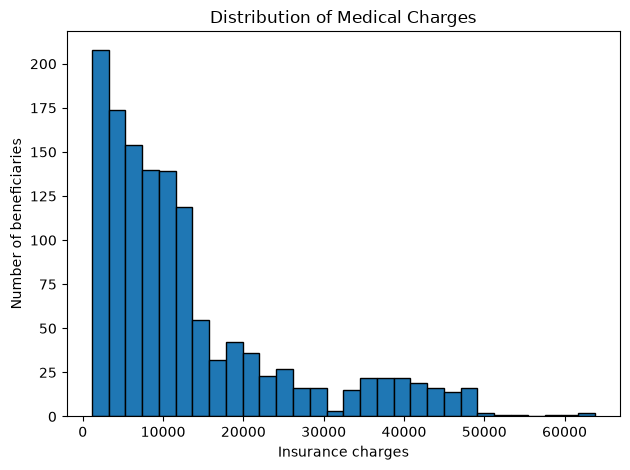

In [5]:
import matplotlib.pyplot as plt

plt.hist(df["charges"], bins=30, edgecolor="black")
plt.xlabel("Insurance charges")
plt.ylabel("Number of beneficiaries")
plt.title("Distribution of Medical Charges")
plt.tight_layout()
plt.show()

### Interpretation
The distribution of insurance charges is strongly right-skewed: most beneficiaries have relatively low charges, while a smaller group has much higher charges.

Mean: 13,270.42
Median: 9,382.03
Standard deviation: 12,110.01
Range: 1,121.87 to 63,770.43.

The mean is substantially larger than the median, which indicates the influence of high-cost beneficiaries. The median is therefore a better description of a typical charge. The wide range and large standard deviation show considerable variability in medical costs.

### 1.3.2 Charges by smoking status

        count      mean    median
smoker                           
no       1064   8434.27   7345.41
yes       274  32050.23  34456.35


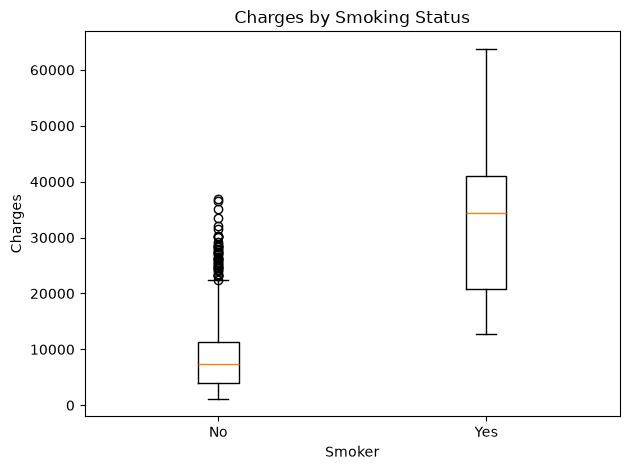

In [6]:
smoking_summary = df.groupby("smoker")["charges"].agg(["count", "mean", "median"])
print(smoking_summary.round(2))

smokers = [df.loc[df["smoker"] == category, "charges"] for category in ["no", "yes"]]
plt.boxplot(smokers, tick_labels=["No", "Yes"])
plt.xlabel("Smoker")
plt.ylabel("Charges")
plt.title("Charges by Smoking Status")
plt.tight_layout()
plt.show()

### Interpretation

Smokers have substantially higher medical charges than non-smokers.

Non-smokers: 1,064 beneficiaries; mean charge $8,434.27; median $7,345.41
Smokers: 274 beneficiaries; mean charge $32,050.23; median $34,456.35.

The box plot shows that both the median and overall distribution of charges are higher among smokers. The mean difference is approximately $23,616, indicating that smoking status is strongly associated with increased medical charges.

This is an observed association and does not by itself establish that smoking causes higher charges.

### 1.3.3 BMI and charges

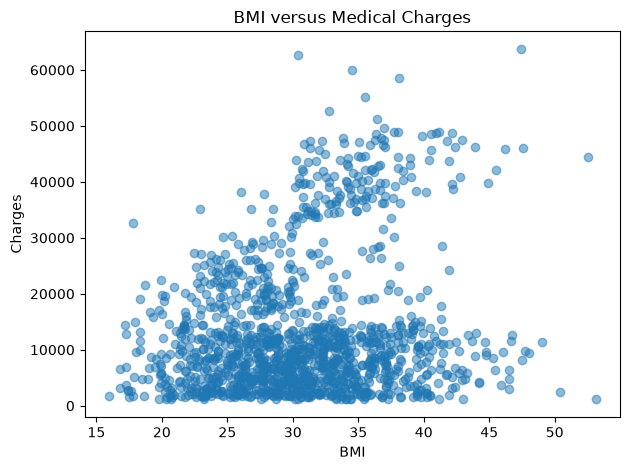

Correlation matrix:
            age    bmi  children  charges
age       1.000  0.109     0.042    0.299
bmi       0.109  1.000     0.013    0.198
children  0.042  0.013     1.000    0.068
charges   0.299  0.198     0.068    1.000


In [7]:
plt.scatter(df["bmi"], df["charges"], alpha=0.5)
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.title("BMI versus Medical Charges")
plt.tight_layout()
plt.show()

print("Correlation matrix:")
print(df[numeric].corr().round(3))

### Interpretation

The scatter plot shows a weak positive relationship between BMI and medical charges: beneficiaries with higher BMI generally tend to have slightly higher charges, but BMI does not reliably predict individual costs.

BMI and charges correlation: 0.198.
Many beneficiaries with similar BMI have substantially different charges.
High charges are especially visible among smokers, suggesting that smoking status may modify the relationship.
The modest correlation indicates that BMI explains little of the variation in charges on its own. The pattern should be interpreted as an association, not as evidence that higher BMI causes higher medical costs.

### 1.3.4 Charges by region

           count      mean    median
region                              
northeast    324  13406.38  10057.65
northwest    325  12417.58   8965.80
southeast    364  14735.41   9294.13
southwest    325  12346.94   8798.59


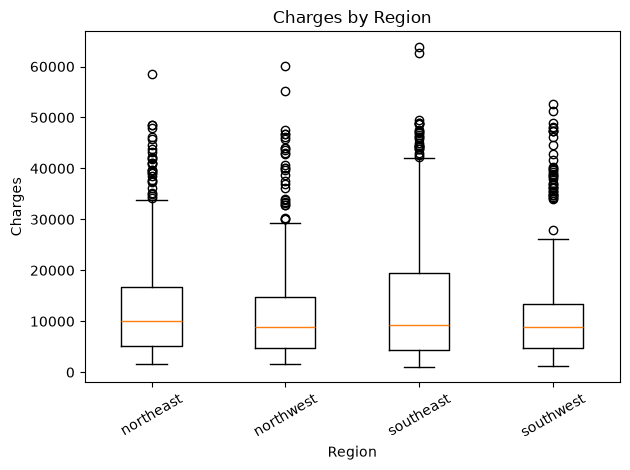

In [8]:
region_summary = df.groupby("region")["charges"].agg(["count", "mean", "median"])
print(region_summary.round(2))

regions = sorted(df["region"].dropna().unique())
region_charges = [df.loc[df["region"] == region, "charges"] for region in regions]
plt.boxplot(region_charges, tick_labels=regions)
plt.xlabel("Region")
plt.ylabel("Charges")
plt.title("Charges by Region")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretation

The box plots show some differences in medical charges across regions, but the regional differences are relatively small compared with the effect of smoking status.

Southeast: highest mean charge, approximately $14,735;
Northeast: mean approximately $13,406;
Northwest: mean approximately $12,418; and
Southwest: mean approximately $12,347.

The southeast has the highest median and greatest variability, while the other regions have broadly similar distributions. These patterns are descriptive; regional differences may reflect differences in the demographic and health characteristics of beneficiaries rather than a direct regional effect.

### Overall Interpretation

- The distribution of charges is strongly right-skewed, with a smaller group of beneficiaries having very high costs.
- Smoking status is a visibly important factor: smokers have a much higher median and mean charge than non-smokers.
- BMI and charges have a weak positive linear association in the full dataset, but the relationship may be stronger among smokers.
- Regional differences in mean and median charges are smaller than the difference between smokers and non-smokers.

## 2 Research questions

### 2.1 Research questions proposed without AI 

1. Is there a statistically significant association between age and BMI?

Rationale: Body Mass Index (BMI) is a primary physiological risk indicator in health insurance underwriting. It is important to determine whether body composition changes as primary beneficiaries age. This question can be addressed by using the Pearson correlation test.

2. To what extent do demographic (age, gender, number of children & BMI), lifestyle (smoking), and regional characteristics explain and predict medical charges by a multiple linear regression model?

Rationale: Health insurance pricing relies on identifying which patient attributes contribute most significantly to overall claims. Using charges as the dependent variable, a multiple ordinary least squares (OLS) regression model can be fitted using both numerical predictors (age, BMI, children) and dummy predictors (sex, smoker, region).

3. Is there a statistically significant association between the number of children and medical charges?

Rationale: Theoretically, the number of children does not directly affect the physiological health of the primary beneficiary. A correlation test is used to test whether family size independently influences individual medical costs. 



### 2.2 Research questions proposed with AI

1. How do medical charges differ between smokers and non-smokers?
2. Is BMI associated with higher medical charges, and does this relationship differ by smoking status?
3. How do age and the number of dependents contribute to the variation in charges?

Prompt used: Propose three research questions from the file "MedicalCost.csv" and explain why they are practical/business-relevant and answerable with the assigned data using common statistical methods.

### 2.3 Compare and decide the Human Intelligence (HI) and AI questions

After careful consideration, the three AI proposed questions were selected for further exploration. In terms of feasibility, both the HI and AI proposed questions are answerable using appropriate statistical methods. However, the HI questions were primarily driven by intuitive curiosity. The AI questions adopted a more holistic, actuarial perspective aimed at uncovering the principal drivers of medical charges. Furthermore, when guided by well specified prompts, the AI provided clear methodological rationales and proposed statistical testing methods. Therefore, the three AI proposed research questions presented in Section 2.2, are further modified and presented below:

**Research question 1: Do smokers have higher medical charges than non-smokers?**  
This directly compares two policy-relevant groups and can be investigated with summary statistics and a box plot.

**Research question 2: Is BMI associated with higher charges after accounting for smoking status?**  
This asks whether BMI remains informative when the strongest observed categorical factor is considered.

**Research question 3: How do age, BMI, children, sex, smoking status, and region jointly relate to charges?**  
This broader question motivates a multivariable model and allows us to compare relative associations across variables.

## 2.4 Appropriate analyses for the three selected research questions

The following analyses address the three questions stated in Section 2.3. Inferential models use heteroskedasticity-robust (HC3) standard errors because the charge distribution is highly right-skewed and group variances differ.

### Research question 1: Do smokers have higher medical charges than non-smokers?

**Method:** Report group means, medians, and sample sizes; compare the groups with a Welch two-sample t-test (which does not assume equal variances), and show the mean difference with a 95% confidence interval. A Mann-Whitney test is included as a robustness check because charges are strongly skewed.

In [8]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

non_smoker = df.loc[df["smoker"] == "no", "charges"]
smoker = df.loc[df["smoker"] == "yes", "charges"]

rq1_summary = df.groupby("smoker")["charges"].agg(["count", "mean", "median", "std"])
print(rq1_summary.round(2))

welch = stats.ttest_ind(smoker, non_smoker, equal_var=False)
difference = smoker.mean() - non_smoker.mean()
se = np.sqrt(smoker.var(ddof=1) / len(smoker) + non_smoker.var(ddof=1) / len(non_smoker))
df_welch = (smoker.var(ddof=1) / len(smoker) + non_smoker.var(ddof=1) / len(non_smoker))**2 / (
    (smoker.var(ddof=1) / len(smoker))**2 / (len(smoker) - 1)
    + (non_smoker.var(ddof=1) / len(non_smoker))**2 / (len(non_smoker) - 1)
)
critical = stats.t.ppf(0.975, df_welch)
ci = (difference - critical * se, difference + critical * se)
mann_whitney = stats.mannwhitneyu(smoker, non_smoker, alternative="two-sided")

print(f"Smoker minus non-smoker mean difference: ${difference:,.2f}")
print(f"Welch 95% CI: (${ci[0]:,.2f}, ${ci[1]:,.2f})")
print(f"Welch t-test: t = {welch.statistic:.3f}, df = {welch.df:.1f}, p = {welch.pvalue:.3g}")
print(f"Mann-Whitney test: U = {mann_whitney.statistic:.0f}, p = {mann_whitney.pvalue:.3g}")

        count      mean    median       std
smoker                                     
no       1064   8434.27   7345.41   5993.78
yes       274  32050.23  34456.35  11541.55
Smoker minus non-smoker mean difference: $23,615.96
Welch 95% CI: ($22,197.21, $25,034.71)
Welch t-test: t = 32.752, df = 311.9, p = 5.89e-103
Mann-Whitney test: U = 284133, p = 5.27e-130


**Conclusion:** The Welch test tests whether mean charges differ, while the Mann-Whitney test provides a distribution-sensitive sensitivity analysis. Interpret a statistically significant difference as an association rather than a causal effect.

### Research question 2: Is BMI associated with higher charges after accounting for smoking status?

**Method:** Fit an OLS model with charges as the outcome and BMI, smoking status, and their interaction as predictors. The interaction is the key test: it asks whether the BMI slope differs between smokers and non-smokers. HC3 standard errors are used.

                   Coefficient     HC3 SE  95% CI Low  95% CI High  p-value
Intercept            5879.4241   885.4027   4144.0667    7614.7815   0.0000
smoker[T.yes]      -19066.0004  2387.8594 -23746.1188  -14385.8820   0.0000
bmi                    83.3506    28.6098     27.2763     139.4248   0.0036
bmi:smoker[T.yes]    1389.7557    78.6035   1235.6956    1543.8158   0.0000
Estimated BMI slope for non-smokers: $83.35 per BMI point
Estimated BMI slope for smokers: $1,473.11 per BMI point
RQ2 adjusted R-squared: 0.741


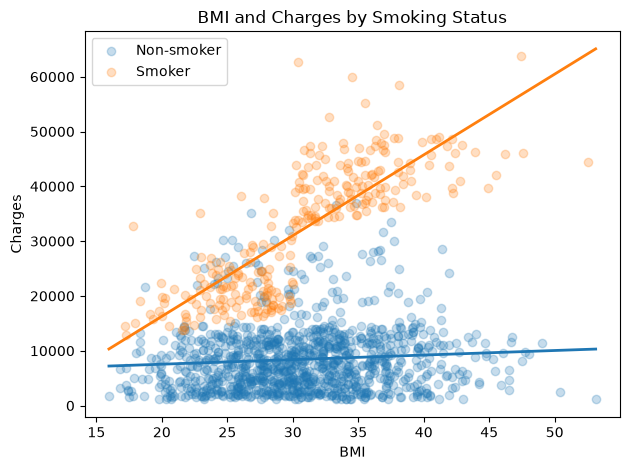

In [9]:
rq2_model = smf.ols(
    "charges ~ bmi + smoker + bmi:smoker",
    data=df,
).fit(cov_type="HC3")

rq2_terms = rq2_model.params.to_frame("Coefficient")
rq2_terms["HC3 SE"] = rq2_model.bse
rq2_terms["95% CI Low"] = rq2_model.conf_int()[0]
rq2_terms["95% CI High"] = rq2_model.conf_int()[1]
rq2_terms["p-value"] = rq2_model.pvalues
print(rq2_terms.round(4))

bmi_slope_no = rq2_model.params["bmi"]
bmi_slope_yes = rq2_model.params["bmi"] + rq2_model.params["bmi:smoker[T.yes]"]
print(f"Estimated BMI slope for non-smokers: ${bmi_slope_no:,.2f} per BMI point")
print(f"Estimated BMI slope for smokers: ${bmi_slope_yes:,.2f} per BMI point")
print(f"RQ2 adjusted R-squared: {rq2_model.rsquared_adj:.3f}")

bmi_grid = np.linspace(df["bmi"].min(), df["bmi"].max(), 200)
plt.scatter(df.loc[df["smoker"] == "no", "bmi"], df.loc[df["smoker"] == "no", "charges"], alpha=0.25, label="Non-smoker")
plt.scatter(df.loc[df["smoker"] == "yes", "bmi"], df.loc[df["smoker"] == "yes", "charges"], alpha=0.25, label="Smoker")
plt.plot(bmi_grid, rq2_model.params["Intercept"] + rq2_model.params["bmi"] * bmi_grid, linewidth=2)
plt.plot(bmi_grid,
         rq2_model.params["Intercept"] + rq2_model.params["smoker[T.yes]"]
         + (rq2_model.params["bmi"] + rq2_model.params["bmi:smoker[T.yes]"]) * bmi_grid,
         linewidth=2)
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.title("BMI and Charges by Smoking Status")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** The BMI coefficient represents the BMI slope for non-smokers. The interaction coefficient tests whether the smoker slope differs from that baseline. A positive and statistically significant interaction indicates that higher BMI is associated with more additional charge among smokers than among non-smokers.

### Research question 3: How do age, BMI, children, sex, smoking status, and region jointly relate to charges?

**Method:** Fit a multivariable OLS model containing all six predictors, with an interaction between BMI and smoking status. Reporting HC3 95% confidence intervals and p-values avoids overstating the precision of coefficients under heteroskedasticity and skew.

                     Coefficient     HC3 SE  95% CI Low  95% CI High  p-value
Intercept             -2223.4539   780.6892  -3753.5767    -693.3312   0.0044
sex[T.male]            -500.1460   267.4868  -1024.4105      24.1186   0.0615
smoker[T.yes]        -20415.6112  1953.1994 -24243.8118  -16587.4106   0.0000
region[T.northwest]    -585.4780   405.2424  -1379.7386     208.7825   0.1485
region[T.southeast]   -1210.1312   402.1648  -1998.3597    -421.9027   0.0026
region[T.southwest]   -1231.1077   371.6068  -1959.4436    -502.7719   0.0009
age                     263.6202     9.6267    244.7523     282.4882   0.0000
bmi                      23.5329    22.5875    -20.7379      67.8036   0.2975
bmi:smoker[T.yes]      1443.0964    63.2886   1319.0531    1567.1397   0.0000
children                516.4034   103.5279    313.4924     719.3144   0.0000
R-squared: 0.841
Adjusted R-squared: 0.840
Sample size: 1338


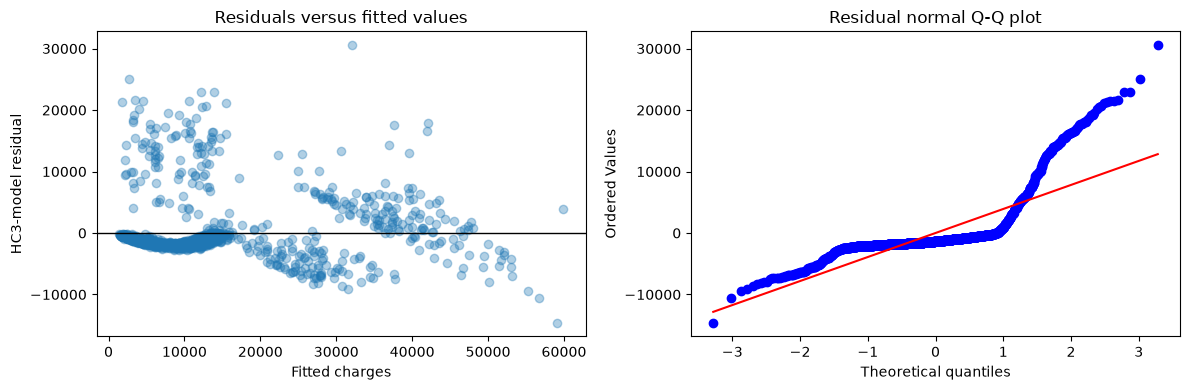

In [10]:
rq3_model = smf.ols(
    "charges ~ age + sex + bmi + children + smoker + region + bmi:smoker",
    data=df,
).fit(cov_type="HC3")

rq3_terms = rq3_model.params.to_frame("Coefficient")
rq3_terms["HC3 SE"] = rq3_model.bse
rq3_terms["95% CI Low"] = rq3_model.conf_int()[0]
rq3_terms["95% CI High"] = rq3_model.conf_int()[1]
rq3_terms["p-value"] = rq3_model.pvalues
print(rq3_terms.round(4))
print(f"R-squared: {rq3_model.rsquared:.3f}")
print(f"Adjusted R-squared: {rq3_model.rsquared_adj:.3f}")
print(f"Sample size: {int(rq3_model.nobs)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(rq3_model.fittedvalues, rq3_model.resid, alpha=0.35)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Fitted charges")
axes[0].set_ylabel("HC3-model residual")
axes[0].set_title("Residuals versus fitted values")

stats.probplot(rq3_model.resid, dist="norm", plot=axes[1])
axes[1].set_title("Residual normal Q-Q plot")
plt.tight_layout()
plt.show()

**Conclusion:** The multivariable model estimates each predictor's association with charges while holding the other listed predictors constant. In particular, coefficients for categorical variables compare each represented category with the model's reference category. Because charges are highly skewed, emphasize effect sizes and confidence intervals and do not interpret coefficients as causal effects.

## 3 Human–AI partnership reflection

3.1 Learning Python when AI can generate code

Before this course, I had no background in Python. I understood that Python was the primary language underpinning modern artificial intelligence, but technical terms such as GitHub, Jupyter Notebook, and TensorFlow felt completely alien.

I see that learning Python fundamentals remains indispensable. An analogy is the scientific calculator: a calculator handles calculation processes, but users must still understand mathematical fundamentals and logics to input the numbers and judge whether the output is plausible. Similarly, GitHub Copilot can translate natural language prompts into executable scripts, but the human user remains responsible for spotting hallucinations, diagnosing execution errors, and verifying the results. Without basic Python literacy, one cannot evaluate or debug AI generates. With GitHub Copilot, a beginner no longer struggles through syntax rules but still need to know the basics.

3.2 The environment I worked in

This course also marked my first experience with an IDE. Working in GitHub Codespaces was a mix of overwhelming and convenient. The interface was initially overwhelming for someone like me without a technical and programming background. On the other hand, it was convenient because it minimises local configuration. Libraries, dependencies and environment files were pre-configured and users can access through a web browser. One thing that I found most challenging was navigating the complex multi-pane layout and the file management system. It took me a while to figure out how to save and share the files with others. It is also challenging to keep track of the repository file explorer, active notebook tabs, and terminal commands simultaneously. Conversely, I found one very useful feature was the integrated Jupyter Notebook interface paired with in-line execution, that can write and run code cell by cell. 

Despite these advantages, constraints remain. Cloud-hosted environments rely entirely on stable network connectivity. Unexpected service interruptions or platform outages can bring productivity to a complete standstill. Besides, complex analyses consume significant tokens. 

3.3 My judgement in this case study

3.3.1 A working belief I tested

I began with the belief about a pattern in the data, that the BMI of an individual would have a strong, positive correlation with their medical charges. Specifically, I expected that individuals whose BMI falls within the recommended range of 18.5 to 24.9 would incur significantly lower charges than those who are overweight or obese (BMI > 24.9), as higher BMI is associated with greater chronic health risks. 

To test this belief, I constructed a scatter plot of BMI (horizontal axis) against Charges (vertical axis) (see Section 1.3.3). The scatter plot did not show a clean, continuous upward trend. Instead, the points split into distinct bands. A dense concentration of data points remained flat along the bottom of the plot (under $10,000), even for individuals with high BMIs of 35 or 40. Meanwhile, a separate upper cluster showed charges surging past $30,000 to $40,000. High BMI alone was clearly not causing a steady, uniform rise in charges.

I revised my belief. High BMI alone does not drive high healthcare costs. Instead, smoking status acts as a compounding factor; high BMI may escalate medical charges dramatically when paired with smoking (Section 1.3.2 considers smoking status and charges only). Therefore, my revised belief is that BMI and smoking must be considered together rather than as independent linear drivers.

This outcome matters because assuming a simple, direct relationship between BMI and medical charges would lead to model misspecification and flawed conclusions. For insurers and decision makers, penalising high BMI policyholders uniformly without considering smoking status would misjudge actuarial risk and unfairly misprice premiums.

3.3.2 Copilot suggestion I evaluated

I asked Copilot "What statistical test should I use to determine whether there is a significant difference in medical charges between smokers and non-smokers?" Copilot selected GPT-6 Luna and answered: "Use a Welch two-sample t-test to compare the average medical charges for smokers and non-smokers. It allows the groups to have different variances, which is sensible here.

Medical charges are often right-skewed, so check the distributions and report group summaries (means and confidence interval). If your question is about a typical charge rather than the mean, consider a Mann–Whitney U test—though it tests for a difference in distributions, not specifically medians."

How I evaluated the suggestion: I evaluated Copilot’s suggestion by inputing the same question to two other AI models, viz. Gemini-3.8 and POE Assistant, and asked them to evaluate the suggestion given by Copilot. The two AI models concurred with Copilot's suggestion and provided explanation.

What I kept, changed, and why:
I kept Copilot’s code for filtering and splitting the dataset into smoker and non-smoker subsets. However, I changed the test itself: because the charges data was severely right-skewed and Levene's test revealed significant heteroscedasticity (p<0.001), a standard Student's t-test was invalid. Instead, I modified the code to use Welch’s t-test (equal_var=False) and cross-checked the result using a non-parametric Mann-Whitney U test (scipy.stats.mannwhitneyu) to ensure robust conclusions.

3.3.3 How Copilot affected my speed and confidence

All in all, Copilot greatly accelerated and moderately enhanced my confidence when I carried out the exploratory and statistical analyses. The analysis cannot be fully automated and depend solely on AI. Still, a human has to verify and validate the AI judgements.

## Reference

Medical Cost Personal Datasets — https://www.kaggle.com/datasets/mirichoi0218/insurance

Ott, R. L., & Longnecker, M. T. (2016). _An introduction to statistical methods and data analysis_ (7th ed.). Cengage Learning.